**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [22]:
job_names = ["net_v3_0per_k9", "net_v3_20per_k9", "net_v3_40per_k9", "net_v3_60per_k9", "net_v3_80per_k9"]

def load_job(job_name):
    results_dir = f"/tmp/anomaly_results_pca_{job_name}"          
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_pca_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []        
all_rules = {}      

for job_name in job_names:
    results, df = load_job(job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "job_name": job_name,
        "k": results["k"],
        "varianza_spiegata": results["varianza_spiegata"],
        "min_flood_area": results["min_flood_area"],
        "standardize": results["standardize"],
        "n_fit": results["n_fit"], "n_normali": results["n_normali"], "n_anomale": results["n_anomale"],
        "score_normali": f"{score_normal.mean():.4f} ± {score_normal.std():.4f}",
        "score_anomale": f"{score_anom.mean():.4f} ± {score_anom.std():.4f}",
        "auroc": results["auroc"],
    })
    all_rules[job_name] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index("job_name")
df_rules = pd.concat(all_rules, names=["job_name", "regola"])      

df_summary

,k,varianza_spiegata,min_flood_area,standardize,n_fit,n_normali,n_anomale,score_normali,score_anomale,auroc
job_name,,,,,,,,,,
net_v3_0per_k9,9,0.314863,0.0,True,2572,2402,2402,-177.1404 ± 40.1925,-207.2152 ± 40.2531,0.703005
net_v3_20per_k9,9,0.314863,20.0,True,2572,1085,1085,-177.4372 ± 38.8124,-217.9328 ± 35.0641,0.782344
net_v3_40per_k9,9,0.314863,40.0,True,2572,642,642,-178.8522 ± 39.1107,-219.9716 ± 32.0410,0.791197
net_v3_60per_k9,9,0.314863,60.0,True,2572,359,359,-178.9329 ± 39.0932,-219.8283 ± 31.3952,0.793236
net_v3_80per_k9,9,0.314863,80.0,True,2572,173,173,-175.3305 ± 39.7007,-215.5341 ± 28.8624,0.798089


In [23]:
df_rules

soglia      TP     FP  \
job_name        regola                                                   
net_v3_0per_k9  pca score < soglia (FA 5%)  -242.643402   454.0   72.0   
                pca score < soglia (FA 10%) -228.746674   715.0  146.0   
                pca score < soglia (FA 15%) -219.643829   910.0  190.0   
                pca score < soglia (FA 20%) -211.264069  1108.0  249.0   
                pca score < soglia (FA 25%) -203.317673  1302.0  317.0   
                pca score < soglia (FA 30%) -196.502960  1462.0  383.0   
net_v3_20per_k9 pca score < soglia (FA 5%)  -242.890933   248.0   29.0   
                pca score < soglia (FA 10%) -231.082034   368.0   46.0   
                pca score < soglia (FA 15%) -220.205865   512.0   75.0   
                pca score < soglia (FA 20%) -210.808575   627.0  111.0   
                pca score < soglia (FA 25%) -203.701435   715.0  135.0   
                pca score < soglia (FA 30%) -196.991690   787.0  157.0   
net_v3_40per_k9 pca score < soglia (FA 5%)  -244.016617   140.0   21.0   
                pca score < soglia (FA 10%) -231.093048   230.0   36.0   
                pca score < soglia (FA 15%) -220.576691   310.0   55.0   
                pca score < soglia (FA 20%) -211.421539   388.0   75.0   
                pca score < soglia (FA 25%) -203.102249   448.0   89.0   
                pca score < soglia (FA 30%) -197.709747   482.0   94.0   
net_v3_60per_k9 pca score < soglia (FA 5%)  -249.615648    65.0   13.0   
                pca score < soglia (FA 10%) -231.455457   129.0   20.0   
                pca score < soglia (FA 15%) -221.426978   172.0   29.0   
                pca score < soglia (FA 20%) -214.175531   202.0   38.0   
                pca score < soglia (FA 25%) -202.362366   249.0   46.0   
                pca score < soglia (FA 30%) -198.168887   269.0   48.0   
net_v3_80per_k9 pca score < soglia (FA 5%)  -242.506947    26.0    6.0   
                pca score < soglia (FA 10%) -233.830917    45.0    6.0   
                pca score < soglia (FA 15%) -224.124504    68.0    7.0   
                pca score < soglia (FA 20%) -207.092712   105.0   16.0   
                pca score < soglia (FA 25%) -197.314320   125.0   24.0   
                pca score < soglia (FA 30%) -193.557663   138.0   26.0   

                                                 FN      TN   FA_rate  \
job_name        regola                                                  
net_v3_0per_k9  pca score < soglia (FA 5%)   1948.0  1129.0  0.059950   
                pca score < soglia (FA 10%)  1687.0  1055.0  0.121565   
                pca score < soglia (FA 15%)  1492.0  1011.0  0.158201   
                pca score < soglia (FA 20%)  1294.0   952.0  0.207327   
                pca score < soglia (FA 25%)  1100.0   884.0  0.263947   
                pca score < soglia (FA 30%)   940.0   818.0  0.318901   
net_v3_20per_k9 pca score < soglia (FA 5%)    837.0   514.0  0.053407   
                pca score < soglia (FA 10%)   717.0   497.0  0.084715   
                pca score < soglia (FA 15%)   573.0   468.0  0.138122   
                pca score < soglia (FA 20%)   458.0   432.0  0.204420   
                pca score < soglia (FA 25%)   370.0   408.0  0.248619   
                pca score < soglia (FA 30%)   298.0   386.0  0.289134   
net_v3_40per_k9 pca score < soglia (FA 5%)    502.0   300.0  0.065421   
                pca score < soglia (FA 10%)   412.0   285.0  0.112150   
                pca score < soglia (FA 15%)   332.0   266.0  0.171340   
                pca score < soglia (FA 20%)   254.0   246.0  0.233645   
                pca score < soglia (FA 25%)   194.0   232.0  0.277259   
                pca score < soglia (FA 30%)   160.0   227.0  0.292835   
net_v3_60per_k9 pca score < soglia (FA 5%)    294.0   167.0  0.072222   
                pca score < soglia (FA 10%)   230.0   160.0  0.111111   
                pca score < soglia (FA 15%)   187.0   151.0  0.161111   
 

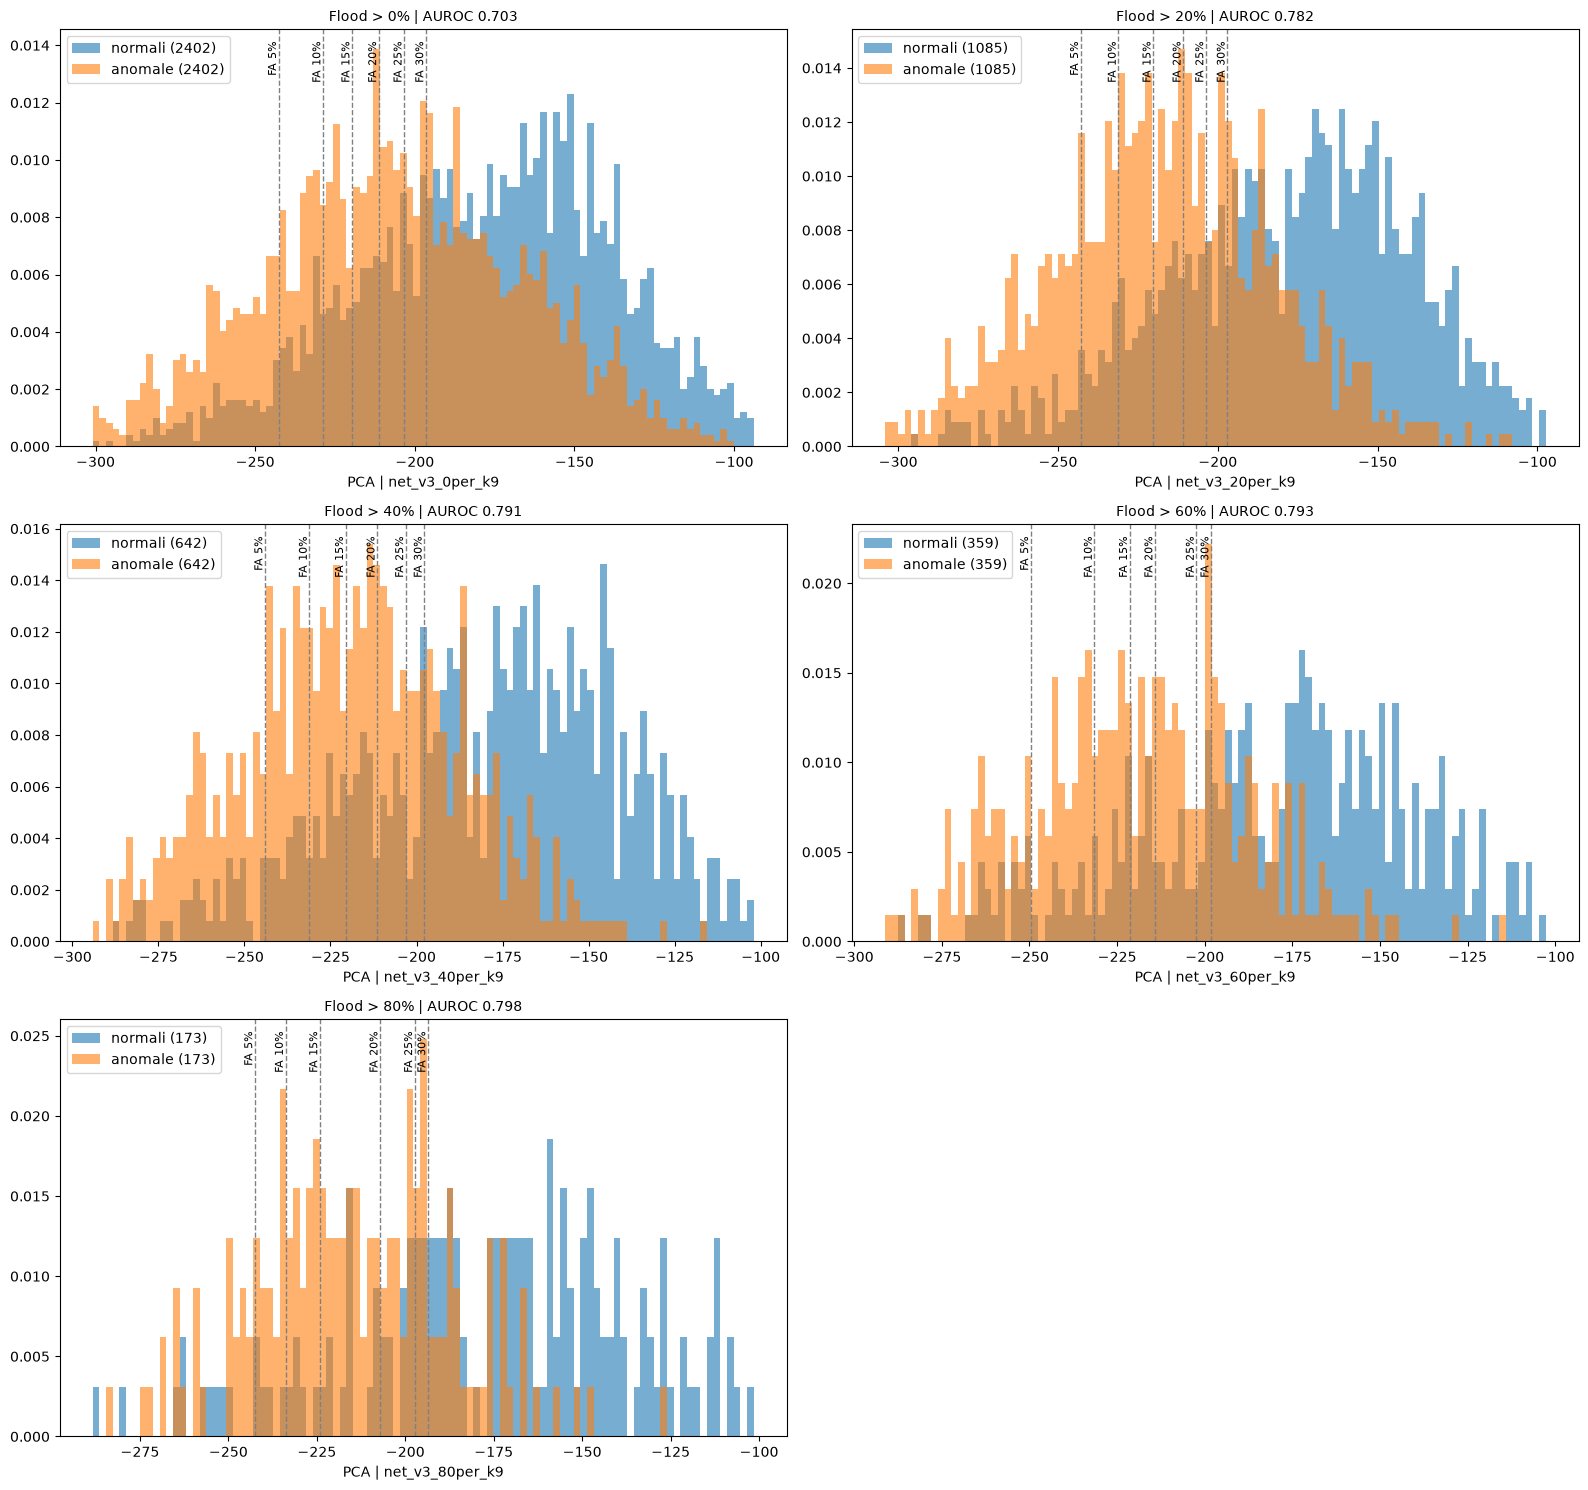

In [24]:
def plot_hist(ax, job_name, results, df):
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])               
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
    for nome, r in results["rules"].items():                     
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)
    ax.set_xlabel(f"PCA | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=10)


n_cols = 2
n_rows = int(np.ceil(len(job_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

for ax, job_name in zip(axes.flat, job_names):
    results, df = load_job(job_name)
    plot_hist(ax, job_name, results, df)

for ax in axes.flat[len(job_names):]:                           
    ax.axis("off")

plt.tight_layout()
plt.show()

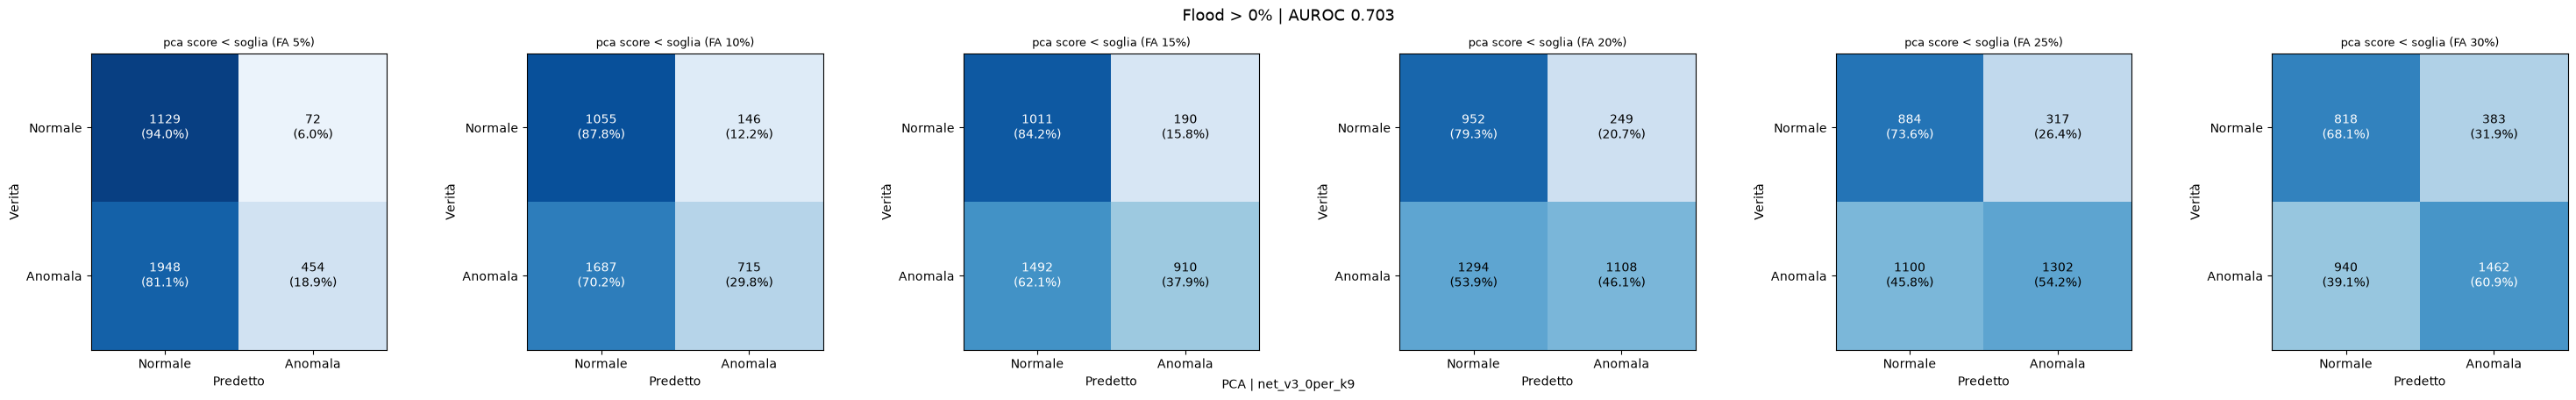

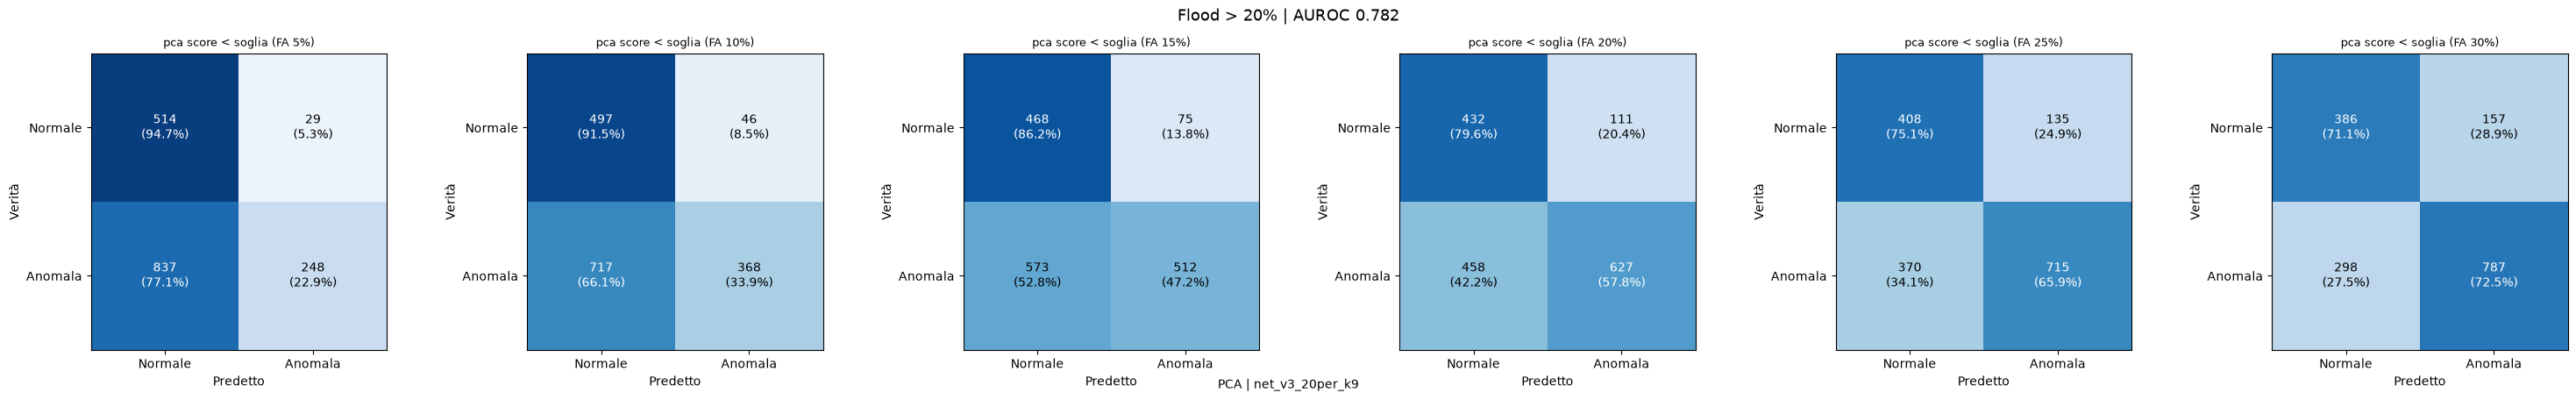

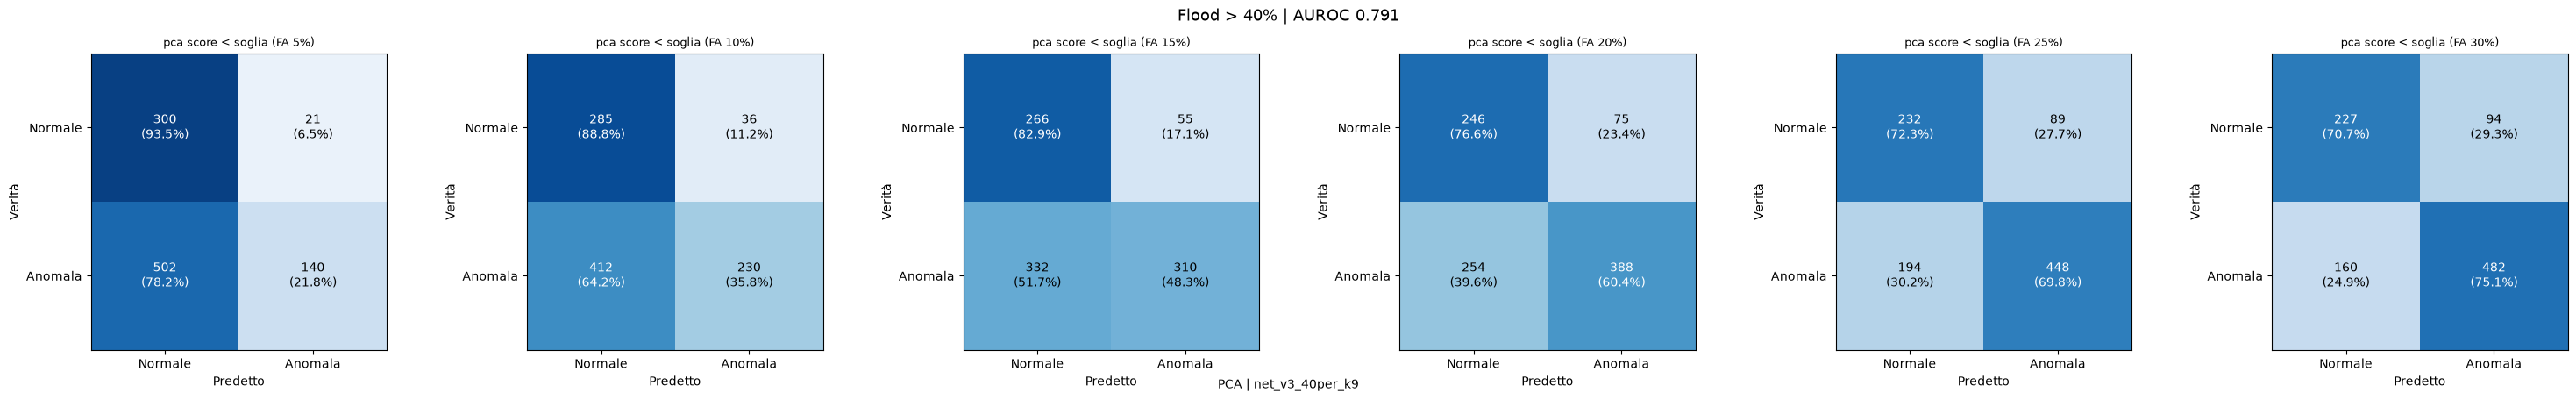

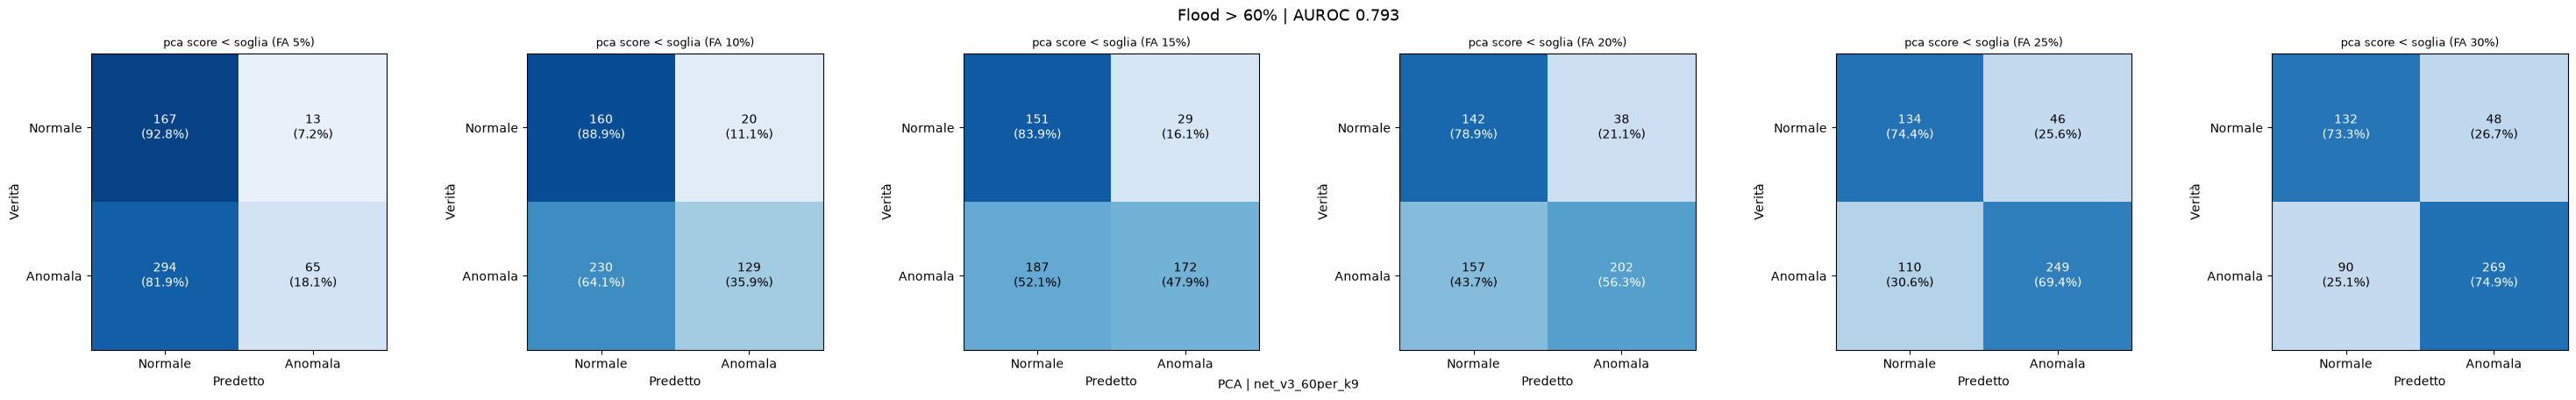

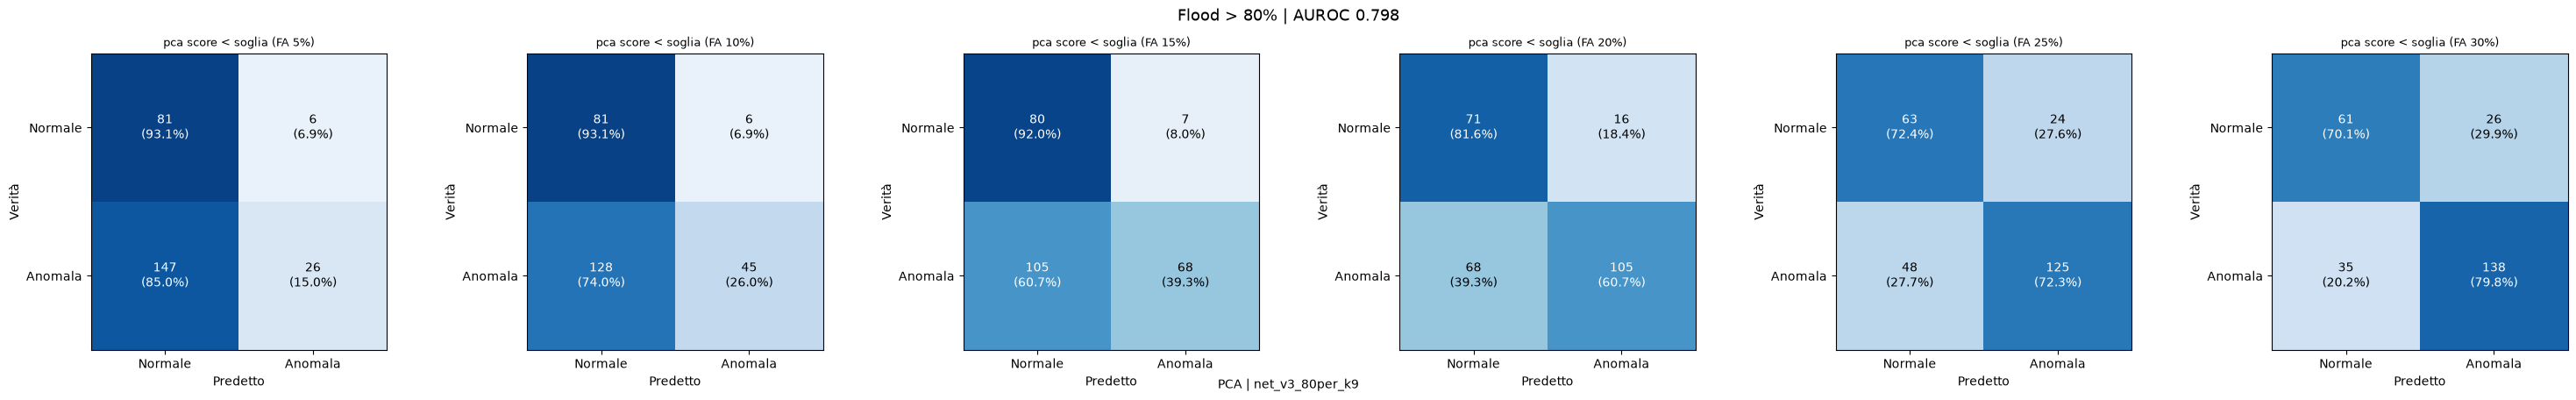

In [25]:
def plot_confusion(job_name, results):
    rules = results["rules"]
    fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

    for ax, (nome, r) in zip(axes[0], rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
    fig.text(0.5, 0.01, f"PCA | {job_name}", ha="center", va="bottom", fontsize=10)
    plt.tight_layout()
    plt.show()


for job_name in job_names:
    results, df = load_job(job_name)
    plot_confusion(job_name, results)